In [1]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
import time

from sklearn.metrics import accuracy_score, f1_score, classification_report

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Device utilisé:", device)

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
GPU disponible: True
GPU: Tesla T4
Device utilisé: cuda


In [2]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split

transform = transforms.ToTensor()

train_full = datasets.MNIST(
    root="/kaggle/working/data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="/kaggle/working/data",
    train=False,
    download=True,
    transform=transform
)

# Séparer les données d'entraînement et de validation
train_size = 54000
val_size = 6000

train_dataset, val_dataset = random_split(
    train_full,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

batch_size = 128

train_loader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True,
    num_workers=2, pin_memory=True
)

val_loader = DataLoader(
    val_dataset, batch_size=batch_size, shuffle=False,
    num_workers=2, pin_memory=True
)

test_loader = DataLoader(
    test_dataset, batch_size=batch_size, shuffle=False,
    num_workers=2, pin_memory=True
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

100%|██████████| 9.91M/9.91M [00:00<00:00, 39.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.02MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.33MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.59MB/s]

Train: 54000
Validation: 6000
Test: 10000


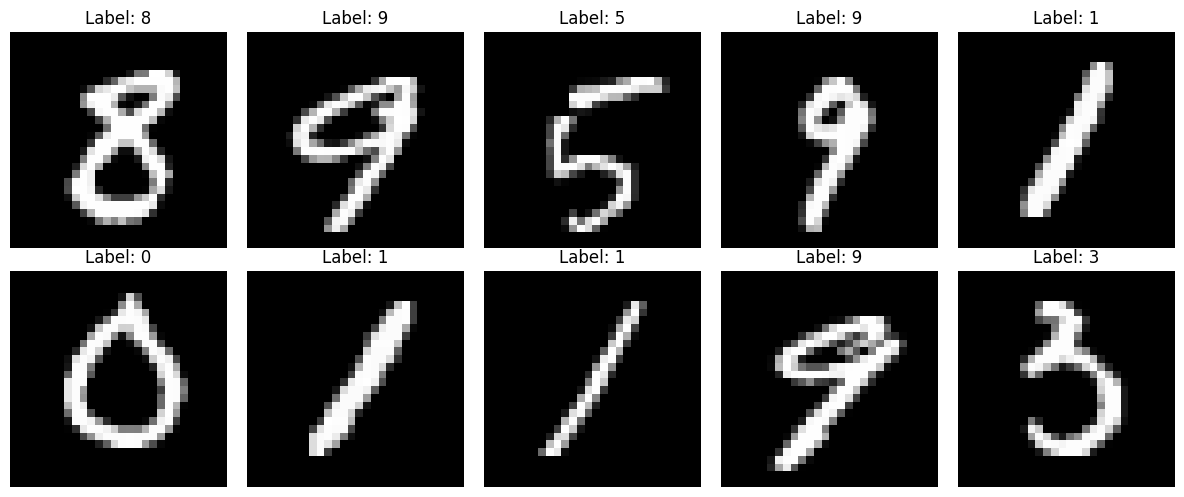

In [3]:
images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label: {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim

class CNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # Image: 1 x 28 x 28
            nn.Conv2d(
                in_channels=1,
                out_channels=32,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # 32 x 14 x 14
            nn.Conv2d(
                in_channels=32,
                out_channels=64,
                kernel_size=3,
                stride=1,
                padding=1
            ),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)

            # Output: 64 x 7 x 7
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(p=0.3),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = CNN().to(device)

print(model)
print("\nDevice:", device)
print(
    "Nombre de paramètres:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

CNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)

Device: cuda
Nombre de paramètres: 421642


In [5]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=1e-4
)

num_epochs = 10

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

print("Modèle prêt pour l'entraînement.")
print("Optimiseur: Adam")
print("Learning rate: 0.001")
print("Epochs:", num_epochs)

Modèle prêt pour l'entraînement.
Optimiseur: Adam
Learning rate: 0.001
Epochs: 10


In [6]:
import time
for epoch in range(num_epochs):
    start_time = time.time()

    # -------------------------
    # TRAINING
    # -------------------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_train_loss = running_loss / total
    epoch_train_acc = correct / total

    # -------------------------
    # VALIDATION
    # -------------------------
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    epoch_val_loss = val_running_loss / val_total
    epoch_val_acc = val_correct / val_total

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    train_accuracies.append(epoch_train_acc)
    val_accuracies.append(epoch_val_acc)

    elapsed = time.time() - start_time

    print(
        f"Epoch [{epoch+1:02d}/{num_epochs}] "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Train Acc: {epoch_train_acc:.4f} | "
        f"Val Acc: {epoch_val_acc:.4f} | "
        f"Time: {elapsed:.1f}s"
    )

Epoch [01/10] Train Loss: 0.3055 | Val Loss: 0.0824 | Train Acc: 0.9045 | Val Acc: 0.9768 | Time: 8.4s
Epoch [02/10] Train Loss: 0.0856 | Val Loss: 0.0664 | Train Acc: 0.9738 | Val Acc: 0.9808 | Time: 5.5s
Epoch [03/10] Train Loss: 0.0624 | Val Loss: 0.0508 | Train Acc: 0.9811 | Val Acc: 0.9842 | Time: 5.9s
Epoch [04/10] Train Loss: 0.0516 | Val Loss: 0.0424 | Train Acc: 0.9841 | Val Acc: 0.9862 | Time: 5.7s
Epoch [05/10] Train Loss: 0.0415 | Val Loss: 0.0615 | Train Acc: 0.9869 | Val Acc: 0.9813 | Time: 5.6s
Epoch [06/10] Train Loss: 0.0365 | Val Loss: 0.0517 | Train Acc: 0.9885 | Val Acc: 0.9847 | Time: 5.8s
Epoch [07/10] Train Loss: 0.0330 | Val Loss: 0.0406 | Train Acc: 0.9896 | Val Acc: 0.9893 | Time: 5.5s
Epoch [08/10] Train Loss: 0.0309 | Val Loss: 0.0397 | Train Acc: 0.9901 | Val Acc: 0.9887 | Time: 5.7s
Epoch [09/10] Train Loss: 0.0293 | Val Loss: 0.0378 | Train Acc: 0.9907 | Val Acc: 0.9902 | Time: 5.6s
Epoch [10/10] Train Loss: 0.0255 | Val Loss: 0.0380 | Train Acc: 0.9915 |

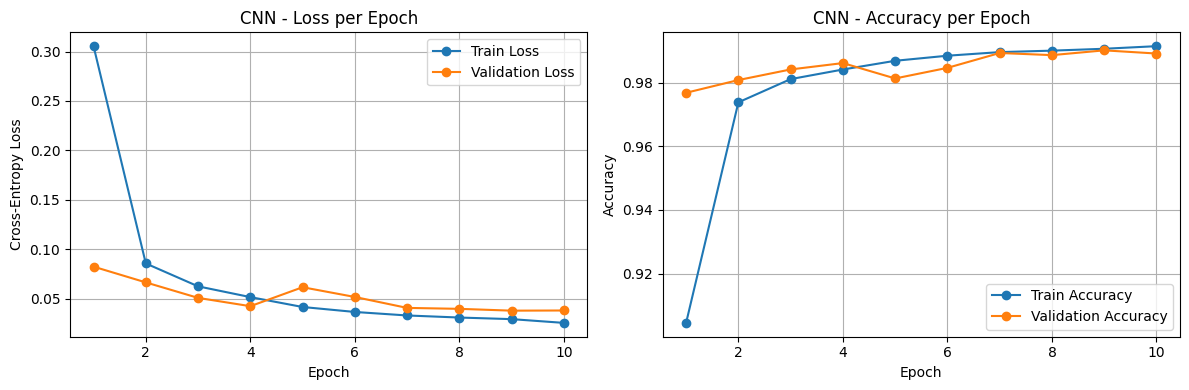

In [7]:
epochs = range(1, num_epochs + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, marker="o", label="Train Loss")
plt.plot(epochs, val_losses, marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("CNN - Loss per Epoch")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, marker="o", label="Train Accuracy")
plt.plot(epochs, val_accuracies, marker="o", label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN - Accuracy per Epoch")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [8]:
model.eval()

all_predictions = []
all_labels = []
test_loss_sum = 0.0
test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss_sum += loss.item() * images.size(0)
        test_total += labels.size(0)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_loss = test_loss_sum / test_total

test_accuracy = accuracy_score(
    all_labels, all_predictions
)

test_f1 = f1_score(
    all_labels, all_predictions,
    average="weighted"
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4%}")
print(f"Weighted F1-score: {test_f1:.4f}")

print("\nClassification Report:")
print(classification_report(all_labels, all_predictions))

Test Loss: 0.0264
Test Accuracy: 99.1400%
Weighted F1-score: 0.9914

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       980
           1       0.99      1.00      1.00      1135
           2       0.99      0.99      0.99      1032
           3       1.00      0.99      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.98      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



In [9]:
import torch
import time
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms

# Reprendre les datasets MNIST déjà chargés
# train_dataset et val_dataset doivent exister.

class MNISTDetectionDataset(Dataset):
    def __init__(self, base_dataset):
        self.base_dataset = base_dataset

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        image, digit = self.base_dataset[idx]

        # MNIST: 1 canal -> 3 canaux
        image = image.repeat(3, 1, 1)

        # Bounding box autour des pixels du chiffre
        mask = image[0] > 0.1
        ys, xs = torch.where(mask)

        x_min = xs.min().item()
        y_min = ys.min().item()
        x_max = xs.max().item() + 1
        y_max = ys.max().item() + 1

        boxes = torch.tensor(
            [[x_min, y_min, x_max, y_max]],
            dtype=torch.float32
        )

        # Label 0 réservé au background
        labels = torch.tensor([int(digit) + 1],
                              dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([idx]),
            "area": torch.tensor(
                [(x_max - x_min) * (y_max - y_min)],
                dtype=torch.float32
            ),
            "iscrowd": torch.tensor([0], dtype=torch.int64)
        }

        return image, target


def detection_collate_fn(batch):
    return tuple(zip(*batch))


train_base = Subset(
    train_dataset,
    range(min(6000, len(train_dataset)))
)

val_base = Subset(
    val_dataset,
    range(min(1000, len(val_dataset)))
)

train_det = MNISTDetectionDataset(train_base)
val_det = MNISTDetectionDataset(val_base)

train_det_loader = DataLoader(
    train_det,
    batch_size=8,
    shuffle=True,
    num_workers=2,
    collate_fn=detection_collate_fn,
    pin_memory=True
)

val_det_loader = DataLoader(
    val_det,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    collate_fn=detection_collate_fn,
    pin_memory=True
)

print("Train:", len(train_det))
print("Validation:", len(val_det))
print("Image shape:", train_det[0][0].shape)
print("Target example:", train_det[0][1])

Train: 6000
Validation: 1000
Image shape: torch.Size([3, 28, 28])
Target example: {'boxes': tensor([[ 5.,  3., 25., 23.]]), 'labels': tensor([7]), 'image_id': tensor([0]), 'area': tensor([400.]), 'iscrowd': tensor([0])}


In [10]:
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights
)
from torchvision.models.detection.faster_rcnn import (
    FastRCNNPredictor
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT

model_det = fasterrcnn_resnet50_fpn(
    weights=weights,
    min_size=64,
    max_size=64,
    box_detections_per_img=10,
    box_score_thresh=0.0
)

in_features = (
    model_det.roi_heads.box_predictor.cls_score.in_features
)

model_det.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    num_classes=11
)

model_det = model_det.to(device)

print("Modèle créé :", type(model_det).__name__)
print("Device :", next(model_det.parameters()).device)

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 195MB/s]


Modèle créé : FasterRCNN
Device : cuda:0


In [11]:

from torch.optim import SGD

optimizer_det = SGD(
    [p for p in model_det.parameters() if p.requires_grad],
    lr=0.001,
    momentum=0.9,
    weight_decay=0.0005
)

num_epochs_det = 5

det_train_losses = []
det_epoch_times = []

print("Optimiseur initialisé.")
print("Historique des pertes initialisé.")
print("Nombre d'epochs :", num_epochs_det)

Optimiseur initialisé.
Historique des pertes initialisé.
Nombre d'epochs : 5


In [12]:

for epoch in range(num_epochs_det):
    model_det.train()

    start = time.time()
    total_loss = 0.0

    for images, targets in train_det_loader:
        images = [img.to(device) for img in images]

        targets = [
            {k: v.to(device) for k, v in target.items()}
            for target in targets
        ]

        loss_dict = model_det(images, targets)
        loss = sum(loss_dict.values())

        optimizer_det.zero_grad()
        loss.backward()
        optimizer_det.step()

        total_loss += loss.item()

    mean_loss = total_loss / len(train_det_loader)
    elapsed = time.time() - start

    det_train_losses.append(mean_loss)
    det_epoch_times.append(elapsed)

    print(
        f"Epoch [{epoch + 1}/{num_epochs_det}] "
        f"Loss: {mean_loss:.4f} "
        f"Time: {elapsed:.1f}s"
    )


Epoch [1/5] Loss: 0.2054 Time: 174.8s
Epoch [2/5] Loss: 0.0725 Time: 178.3s
Epoch [3/5] Loss: 0.0553 Time: 177.7s
Epoch [4/5] Loss: 0.0476 Time: 177.4s
Epoch [5/5] Loss: 0.0416 Time: 177.0s


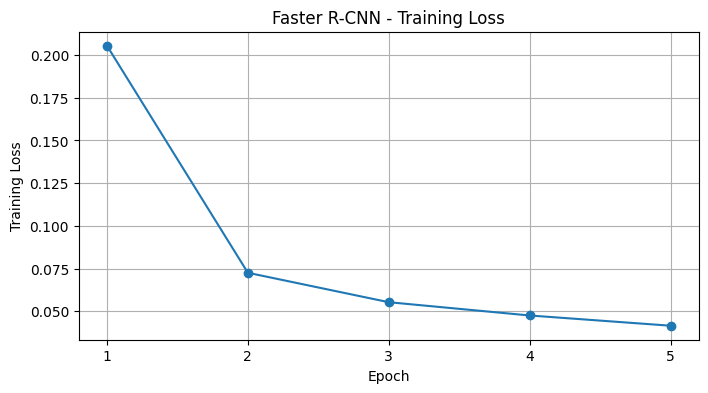

Training losses: [0.20540290408333142, 0.07254942366480828, 0.05532502947251002, 0.04755807497104009, 0.041565851566692194]


In [13]:
plt.figure(figsize=(8, 4))

plt.plot(
    range(1, len(det_train_losses) + 1),
    det_train_losses,
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Faster R-CNN - Training Loss")
plt.xticks(range(1, len(det_train_losses) + 1))
plt.grid(True)
plt.show()

print("Training losses:", det_train_losses)

In [14]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

model_det.eval()

det_true = []
det_pred = []
det_scores = []

with torch.no_grad():
    for images, targets in val_det_loader:
        images = [img.to(device) for img in images]
        outputs = model_det(images)

        for output, target in zip(outputs, targets):
            true_digit = target["labels"].item() - 1

            scores = output["scores"]
            labels = output["labels"]

            if len(scores) == 0:
                # Aucune détection : erreur de classification
                predicted_digit = -1
                best_score = 0.0
            else:
                best_idx = scores.argmax()
                predicted_digit = labels[best_idx].item() - 1
                best_score = scores[best_idx].item()

            det_true.append(true_digit)
            det_pred.append(predicted_digit)
            det_scores.append(best_score)

print(
    "Validation Accuracy:",
    f"{accuracy_score(det_true, det_pred):.4%}"
)

print(
    "Validation Weighted F1:",
    f"{f1_score(det_true, det_pred, average='weighted', labels=list(range(10)), zero_division=0):.4f}"
)

print("\nClassification report:")
print(classification_report(
    det_true,
    det_pred,
    labels=list(range(10)),
    zero_division=0
))

Validation Accuracy: 98.7000%
Validation Weighted F1: 0.9870

Classification report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99       101
           1       1.00      0.98      0.99       114
           2       0.99      0.98      0.98        94
           3       1.00      1.00      1.00        91
           4       0.95      0.99      0.97       100
           5       0.99      1.00      0.99        97
           6       0.98      0.98      0.98       114
           7       0.99      0.99      0.99       101
           8       1.00      0.98      0.99        93
           9       1.00      0.97      0.98        95

    accuracy                           0.99      1000
   macro avg       0.99      0.99      0.99      1000
weighted avg       0.99      0.99      0.99      1000



In [15]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from torchvision.models import VGG16_Weights
import time
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Adapter MNIST au format attendu par VGG16
class MNISTPretrainedDataset(Dataset):
    def __init__(self, base_dataset, image_size=128):
        self.base_dataset = base_dataset
        self.image_size = image_size

        self.mean = torch.tensor(
            [0.485, 0.456, 0.406]
        ).view(3, 1, 1)

        self.std = torch.tensor(
            [0.229, 0.224, 0.225]
        ).view(3, 1, 1)

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        image, label = self.base_dataset[idx]

        # 1 canal -> 3 canaux
        image = image.repeat(3, 1, 1)

        # Redimensionner l'image
        image = F.interpolate(
            image.unsqueeze(0),
            size=(self.image_size, self.image_size),
            mode="bilinear",
            align_corners=False
        ).squeeze(0)

        # Normalisation ImageNet
        image = (image - self.mean) / self.std

        return image, label


train_vgg_dataset = MNISTPretrainedDataset(train_dataset)
val_vgg_dataset = MNISTPretrainedDataset(val_dataset)
test_vgg_dataset = MNISTPretrainedDataset(test_dataset)

train_loader_vgg = DataLoader(
    train_vgg_dataset,
    batch_size=8,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader_vgg = DataLoader(
    val_vgg_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader_vgg = DataLoader(
    test_vgg_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train:", len(train_vgg_dataset))
print("Validation:", len(val_vgg_dataset))
print("Test:", len(test_vgg_dataset))

Train: 54000
Validation: 6000
Test: 10000


In [16]:
# Charger VGG16 avec les poids préentraînés
model_vgg = models.vgg16(weights=VGG16_Weights.DEFAULT)

# Geler les couches convolutionnelles
for param in model_vgg.features.parameters():
    param.requires_grad = False

# Débloquer le dernier bloc convolutionnel
for layer_index, layer in enumerate(model_vgg.features):
    if layer_index >= 24:
        for param in layer.parameters():
            param.requires_grad = True

# Remplacer le classifieur ImageNet par un classifieur à 10 chiffres
model_vgg.classifier = nn.Sequential(
    nn.Linear(512 * 7 * 7, 512),
    nn.ReLU(inplace=True),
    nn.Dropout(0.3),
    nn.Linear(512, 10)
)

model_vgg = model_vgg.to(device)

criterion_vgg = nn.CrossEntropyLoss()

optimizer_vgg = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model_vgg.parameters()),
    lr=1e-4,
    weight_decay=1e-4
)

print("VGG16 prêt sur :", device)
print("Paramètres entraînables :",
      sum(p.numel() for p in model_vgg.parameters()
          if p.requires_grad))

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:02<00:00, 197MB/s]


VGG16 prêt sur : cuda
Paramètres entraînables : 19930122


In [17]:
num_epochs_vgg = 3

vgg_train_losses = []
vgg_val_losses = []
vgg_train_times = []

for epoch in range(num_epochs_vgg):
    start_time = time.time()

    # --------------------
    # Entraînement
    # --------------------
    model_vgg.train()
    running_loss = 0.0
    total_train = 0

    for images, labels in train_loader_vgg:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer_vgg.zero_grad()

        outputs = model_vgg(images)
        loss = criterion_vgg(outputs, labels)

        loss.backward()
        optimizer_vgg.step()

        running_loss += loss.item() * images.size(0)
        total_train += images.size(0)

    train_loss = running_loss / total_train
    vgg_train_losses.append(train_loss)

    # --------------------
    # Validation
    # --------------------
    model_vgg.eval()
    running_val_loss = 0.0
    total_val = 0

    with torch.no_grad():
        for images, labels in val_loader_vgg:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model_vgg(images)
            loss = criterion_vgg(outputs, labels)

            running_val_loss += loss.item() * images.size(0)
            total_val += images.size(0)

    val_loss = running_val_loss / total_val
    vgg_val_losses.append(val_loss)

    elapsed = time.time() - start_time
    vgg_train_times.append(elapsed)

    print(
        f"Epoch [{epoch+1}/{num_epochs_vgg}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Time: {elapsed:.1f}s"
    )

Epoch [1/3] Train Loss: 0.0799 | Val Loss: 0.0450 | Time: 202.7s
Epoch [2/3] Train Loss: 0.0384 | Val Loss: 0.0473 | Time: 202.2s
Epoch [3/3] Train Loss: 0.0290 | Val Loss: 0.0397 | Time: 202.3s


In [18]:
model_vgg.eval()

y_true_vgg = []
y_pred_vgg = []
test_loss_vgg = 0.0
total_test_vgg = 0

with torch.no_grad():
    for images, labels in test_loader_vgg:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model_vgg(images)
        loss = criterion_vgg(outputs, labels)

        predictions = outputs.argmax(dim=1)

        test_loss_vgg += loss.item() * images.size(0)
        total_test_vgg += images.size(0)

        y_true_vgg.extend(labels.cpu().numpy())
        y_pred_vgg.extend(predictions.cpu().numpy())

test_loss_vgg /= total_test_vgg

vgg_accuracy = accuracy_score(y_true_vgg, y_pred_vgg)
vgg_f1 = f1_score(
    y_true_vgg, y_pred_vgg, average="weighted"
)

print(f"VGG16 Test Loss: {test_loss_vgg:.4f}")
print(f"VGG16 Test Accuracy: {vgg_accuracy * 100:.2f}%")
print(f"VGG16 Weighted F1-score: {vgg_f1:.4f}")
print("\nClassification Report:\n")
print(classification_report(y_true_vgg, y_pred_vgg))

VGG16 Test Loss: 0.0436
VGG16 Test Accuracy: 98.89%
VGG16 Weighted F1-score: 0.9889

Classification Report:

              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       0.99      0.99      0.99      1135
           2       1.00      0.98      0.99      1032
           3       0.99      0.99      0.99      1010
           4       0.99      0.98      0.98       982
           5       1.00      0.98      0.99       892
           6       1.00      0.98      0.99       958
           7       0.97      1.00      0.98      1028
           8       0.99      0.99      0.99       974
           9       0.97      0.99      0.98      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



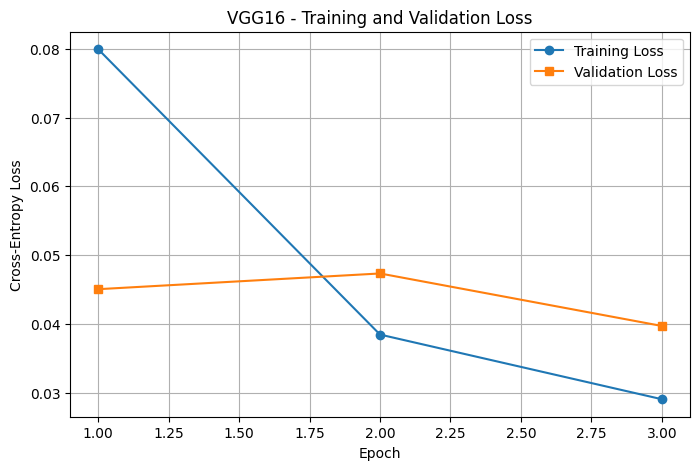

Temps total d'entraînement : 607.2 secondes


In [19]:
import matplotlib.pyplot as plt

epochs = range(1, len(vgg_train_losses) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, vgg_train_losses, marker="o", label="Training Loss")
plt.plot(epochs, vgg_val_losses, marker="s", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("VGG16 - Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

print(f"Temps total d'entraînement : {sum(vgg_train_times):.1f} secondes")

In [20]:
from torchvision.models import alexnet, AlexNet_Weights

model_alex = alexnet(weights=AlexNet_Weights.DEFAULT)

# Geler les couches convolutionnelles
for param in model_alex.features.parameters():
    param.requires_grad = False

# Débloquer les dernières couches convolutionnelles
for layer_index, layer in enumerate(model_alex.features):
    if layer_index >= 8:
        for param in layer.parameters():
            param.requires_grad = True

# Nouveau classifieur pour les 10 chiffres de MNIST
model_alex.classifier = nn.Sequential(
    nn.Dropout(0.3),
    nn.Linear(256 * 6 * 6, 512),
    nn.ReLU(inplace=True),
    nn.Dropout(0.3),
    nn.Linear(512, 10)
)

model_alex = model_alex.to(device)

criterion_alex = nn.CrossEntropyLoss()

optimizer_alex = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model_alex.parameters()),
    lr=1e-4,
    weight_decay=1e-4
)

print("AlexNet prêt sur :", device)
print("Paramètres entraînables :",
      sum(p.numel() for p in model_alex.parameters()
          if p.requires_grad))


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 206MB/s]


AlexNet prêt sur : cuda
Paramètres entraînables : 6199306


In [21]:
num_epochs_alex = 3

alex_train_losses = []
alex_val_losses = []
alex_epoch_times = []

for epoch in range(num_epochs_alex):
    start_time = time.time()

    # Entraînement
    model_alex.train()
    total_loss = 0.0
    total_samples = 0

    for images, labels in train_loader_vgg:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer_alex.zero_grad()

        outputs = model_alex(images)
        loss = criterion_alex(outputs, labels)

        loss.backward()
        optimizer_alex.step()

        total_loss += loss.item() * images.size(0)
        total_samples += images.size(0)

    train_loss = total_loss / total_samples
    alex_train_losses.append(train_loss)

    # Validation
    model_alex.eval()
    val_loss_sum = 0.0
    val_samples = 0

    with torch.no_grad():
        for images, labels in val_loader_vgg:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model_alex(images)
            loss = criterion_alex(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_samples += images.size(0)

    val_loss = val_loss_sum / val_samples
    alex_val_losses.append(val_loss)

    elapsed = time.time() - start_time
    alex_epoch_times.append(elapsed)

    print(
        f"Epoch [{epoch+1}/{num_epochs_alex}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Time: {elapsed:.1f}s"
    )

Epoch [1/3] Train Loss: 0.0767 | Val Loss: 0.0383 | Time: 48.7s
Epoch [2/3] Train Loss: 0.0347 | Val Loss: 0.0498 | Time: 48.4s
Epoch [3/3] Train Loss: 0.0265 | Val Loss: 0.0308 | Time: 50.0s


In [22]:
model_alex.eval()

y_true_alex = []
y_pred_alex = []
test_loss_sum = 0.0
test_samples = 0

with torch.no_grad():
    for images, labels in test_loader_vgg:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model_alex(images)
        loss = criterion_alex(outputs, labels)
        predictions = outputs.argmax(dim=1)

        test_loss_sum += loss.item() * images.size(0)
        test_samples += images.size(0)

        y_true_alex.extend(labels.cpu().numpy())
        y_pred_alex.extend(predictions.cpu().numpy())

alex_test_loss = test_loss_sum / test_samples
alex_accuracy = accuracy_score(y_true_alex, y_pred_alex)
alex_f1 = f1_score(
    y_true_alex, y_pred_alex, average="weighted"
)

print(f"AlexNet Test Loss: {alex_test_loss:.4f}")
print(f"AlexNet Test Accuracy: {alex_accuracy * 100:.2f}%")
print(f"AlexNet Weighted F1-score: {alex_f1:.4f}")
print("\nClassification Report:\n")
print(classification_report(y_true_alex, y_pred_alex))

AlexNet Test Loss: 0.0381
AlexNet Test Accuracy: 99.04%
AlexNet Weighted F1-score: 0.9904

Classification Report:

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.98      1.00      0.99      1032
           3       0.99      1.00      0.99      1010
           4       1.00      0.98      0.99       982
           5       1.00      0.98      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.98      0.99      0.98      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



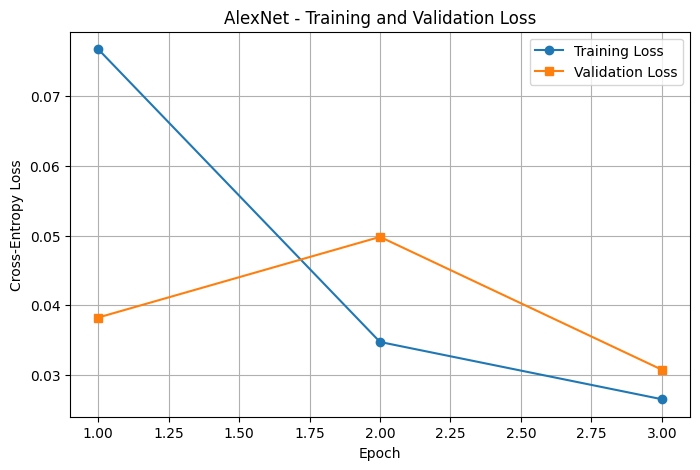

Temps total d'entraînement : 147.1 secondes


In [23]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(alex_train_losses) + 1),
    alex_train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, len(alex_val_losses) + 1),
    alex_val_losses,
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("AlexNet - Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

print(f"Temps total d'entraînement : {sum(alex_epoch_times):.1f} secondes")

In [24]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import time
import matplotlib.pyplot as plt
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
class VisionTransformer(nn.Module):
    def __init__(
        self,
        image_size=28,
        patch_size=7,
        in_channels=1,
        embed_dim=128,
        num_heads=4,
        num_layers=4,
        num_classes=10,
        mlp_dim=256,
        dropout=0.1
    ):
        super().__init__()

        assert image_size % patch_size == 0

        self.num_patches = (image_size // patch_size) ** 2

        # Diviser l'image en patches et projeter chaque patch
        self.patch_embedding = nn.Conv2d(
            in_channels=in_channels,
            out_channels=embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        # Token de classification appris
        self.cls_token = nn.Parameter(
            torch.randn(1, 1, embed_dim) * 0.02
        )

        # Encodage de la position de chaque patch
        self.pos_embedding = nn.Parameter(
            torch.randn(1, self.num_patches + 1, embed_dim) * 0.02
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=mlp_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.norm = nn.LayerNorm(embed_dim)

        self.classifier = nn.Linear(embed_dim, num_classes)

    def forward(self, x):
        # x : [batch, 1, 28, 28]
        x = self.patch_embedding(x)

        # [batch, embed_dim, 4, 4]
        x = x.flatten(2).transpose(1, 2)

        # [batch, 16, embed_dim]
        batch_size = x.shape[0]

        cls_tokens = self.cls_token.expand(batch_size, -1, -1)
        x = torch.cat((cls_tokens, x), dim=1)

        x = x + self.pos_embedding
        x = self.transformer(x)

        # Utiliser le token CLS pour classifier l'image
        x = self.norm(x[:, 0])

        return self.classifier(x)


model_vit = VisionTransformer().to(device)

criterion_vit = nn.CrossEntropyLoss()

optimizer_vit = torch.optim.AdamW(
    model_vit.parameters(),
    lr=3e-4,
    weight_decay=1e-4
)


print("ViT créé sur :", device)
print(
    "Nombre de paramètres :",
    sum(p.numel() for p in model_vit.parameters())
)

GPU: Tesla T4
ViT créé sur : cuda
Nombre de paramètres : 540170


/tmp/ipykernel_23/1989115393.py:58: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


In [25]:
images, labels = next(iter(train_loader))
images = images.to(device)

model_vit.eval()

with torch.no_grad():
    outputs = model_vit(images)

print("Dimensions des images :", images.shape)
print("Dimensions des sorties :", outputs.shape)
print("Exemple de prédiction :", outputs[0].argmax().item())
print("Vrai label :", labels[0].item())

Dimensions des images : torch.Size([128, 1, 28, 28])
Dimensions des sorties : torch.Size([128, 10])
Exemple de prédiction : 5
Vrai label : 7


In [26]:
num_epochs_vit = 10

vit_train_losses = []
vit_val_losses = []
vit_train_times = []

for epoch in range(num_epochs_vit):
    start_time = time.time()

    # Entraînement
    model_vit.train()
    train_loss_sum = 0.0
    train_samples = 0

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer_vit.zero_grad()

        outputs = model_vit(images)
        loss = criterion_vit(outputs, labels)

        loss.backward()
        optimizer_vit.step()

        train_loss_sum += loss.item() * images.size(0)
        train_samples += images.size(0)

    train_loss = train_loss_sum / train_samples
    vit_train_losses.append(train_loss)

    # Validation
    model_vit.eval()
    val_loss_sum = 0.0
    val_samples = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model_vit(images)
            loss = criterion_vit(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_samples += images.size(0)

    val_loss = val_loss_sum / val_samples
    vit_val_losses.append(val_loss)

    elapsed = time.time() - start_time
    vit_train_times.append(elapsed)

    print(
        f"Epoch [{epoch+1}/{num_epochs_vit}] "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Time: {elapsed:.1f}s"
    )

Epoch [1/10] Train Loss: 0.7205 | Val Loss: 0.2945 | Time: 7.6s
Epoch [2/10] Train Loss: 0.2452 | Val Loss: 0.1908 | Time: 7.6s
Epoch [3/10] Train Loss: 0.1720 | Val Loss: 0.1577 | Time: 7.8s
Epoch [4/10] Train Loss: 0.1326 | Val Loss: 0.1251 | Time: 7.8s
Epoch [5/10] Train Loss: 0.1094 | Val Loss: 0.1241 | Time: 7.8s
Epoch [6/10] Train Loss: 0.0963 | Val Loss: 0.1029 | Time: 7.3s
Epoch [7/10] Train Loss: 0.0820 | Val Loss: 0.0988 | Time: 7.8s
Epoch [8/10] Train Loss: 0.0747 | Val Loss: 0.0959 | Time: 7.7s
Epoch [9/10] Train Loss: 0.0661 | Val Loss: 0.0929 | Time: 8.3s
Epoch [10/10] Train Loss: 0.0611 | Val Loss: 0.0893 | Time: 8.0s


In [27]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

model_vit.eval()

y_true_vit = []
y_pred_vit = []
test_loss_sum = 0.0
test_samples = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model_vit(images)
        loss = criterion_vit(outputs, labels)
        predictions = outputs.argmax(dim=1)

        test_loss_sum += loss.item() * images.size(0)
        test_samples += images.size(0)

        y_true_vit.extend(labels.cpu().numpy())
        y_pred_vit.extend(predictions.cpu().numpy())

vit_test_loss = test_loss_sum / test_samples
vit_accuracy = accuracy_score(y_true_vit, y_pred_vit)
vit_f1 = f1_score(
    y_true_vit,
    y_pred_vit,
    average="weighted"
)

print(f"ViT Test Loss: {vit_test_loss:.4f}")
print(f"ViT Test Accuracy: {vit_accuracy * 100:.2f}%")
print(f"ViT Weighted F1-score: {vit_f1:.4f}")
print("\nClassification Report:\n")
print(classification_report(y_true_vit, y_pred_vit))

ViT Test Loss: 0.0850
ViT Test Accuracy: 97.61%
ViT Weighted F1-score: 0.9761

Classification Report:

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.98      0.99      0.99      1135
           2       0.98      0.96      0.97      1032
           3       0.98      0.97      0.98      1010
           4       0.97      0.98      0.98       982
           5       0.98      0.97      0.97       892
           6       0.97      0.97      0.97       958
           7       0.98      0.97      0.98      1028
           8       0.98      0.97      0.97       974
           9       0.97      0.97      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



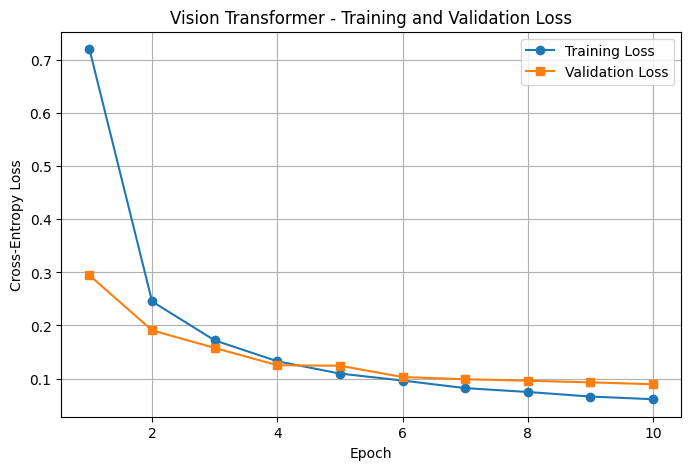

Temps total d'entraînement : 77.8 secondes


In [28]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(vit_train_losses) + 1),
    vit_train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, len(vit_val_losses) + 1),
    vit_val_losses,
    marker="s",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Vision Transformer - Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

print(
    f"Temps total d'entraînement : "
    f"{sum(vit_train_times):.1f} secondes"
)